[Open in Colab](https://colab.research.google.com/github/nz-gravity/sgvb_psd/blob/main/docs/examples/LVK_example.ipynb)

# LVK example

Use a cached 32-second, 4096 Hz public H1 strain file around GW150914
(about 1 MB rather than a long science segment). The fit uses pre-event
noise: 1–5 s for AR training, 6–10 s for SGVB, while the event is at 15.4 s.
Downsample with an anti-aliasing filter to 512 Hz, high-pass at 8 Hz
and analyse 20–200 Hz. The plotted target is this filtered strain PSD;
the explicit high-pass suppresses leakage from the much larger low-frequency
power. Filtering is applied to the continuous segment before the split.
Set `DETECTORS=("H1", "L1")` for a two-detector fit (two small downloads).

[GWOSC event metadata/data](https://gwosc.org/eventapi/json/GWTC-1-confident/GW150914/v3/)
provide the file and event times. Review the quality-mask printout for your
chosen segment; this short demo is not a complete detector-data-quality or
astrophysical-signal analysis. AR coefficients are fitted only on the
separate training block; their uncertainty is held fixed in the reference.
The SGVB spectrum is the reconstructed full strain PSD, not the AR residual PSD.

## Setup

In [1]:
# Colab installs the package; local runs use the project environment.
import subprocess
import sys

try:
    import google.colab
except ImportError:
    print("Using the local SGVB environment. See the repository's uv setup instructions.")
else:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "jax[cpu]==0.6.2", "numpyro==0.19.0",
        "sgvb_psd[examples] @ git+https://github.com/nz-gravity/sgvb_psd.git@main",
    ])


Using the local SGVB environment. See the repository's uv setup instructions.


In [2]:
import warnings
# Progress widgets are unused; ipywidgets is optional in the local environment.
warnings.filterwarnings("ignore", message="IProgress not found.*")

from pathlib import Path
from time import perf_counter
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from sgvb_psd.psd_estimator import PSDEstimator
import jax

%matplotlib inline

plt.rcParams.update({"font.family": "sans-serif", "font.size": 11,
                     "axes.labelsize": 11, "axes.titlesize": 12,
                     "legend.fontsize": 8, "figure.dpi": 110,
                     "text.usetex": False})
print("JAX", jax.__version__, "devices:", jax.devices())
# Deliberately small demonstration budgets, not a convergence certificate.
BUDGET = dict(N_theta=8, nchunks=2, ntrain_map=1000,
              n_elbo_maximisation_steps=300, N_samples=96, seed=7)


20:10:40|SGVB-PSD|INFO| No GPU detected. Running on CPU.
JAX 0.6.2 devices: [CpuDevice(id=0)]


## Data and reference

In [3]:
import h5py
from urllib.request import urlopen
import shutil
DETECTORS = ("H1",)
CACHE = Path("data"); CACHE.mkdir(exist_ok=True)
channels = []; starts = []; spacings = []
for detector in DETECTORS:
    prefix = "H" if detector == "H1" else "L"
    filename = f"{prefix}-{detector}_GWOSC_4KHZ_R1-1126259447-32.hdf5"
    path = CACHE/filename
    if not path.exists():
        url = "https://gwosc.org/eventapi/json/GWTC-1-confident/GW150914/v3/" + filename
        temporary = path.with_suffix(".part")
        with urlopen(url, timeout=60) as response, temporary.open("wb") as destination:
            shutil.copyfileobj(response, destination)
        temporary.replace(path)
    with h5py.File(path, "r") as handle:
        series = handle["strain/Strain"]
        channels.append(series[:])
        starts.append(float(series.attrs["Xstart"]))
        spacings.append(float(series.attrs["Xspacing"]))
        dq = handle["quality/simple/DQmask"]
        names = [v.decode() for v in handle["quality/simple/DQShortnames"][:]]
        required_bits = sum(1 << names.index(name) for name in ("DATA", "CBC_CAT1"))
        dq_time = float(dq.attrs["Xstart"]) + np.arange(len(dq))*float(dq.attrs["Xspacing"])
        used = (dq_time + float(dq.attrs["Xspacing"]) > starts[-1]+1) & (dq_time < starts[-1]+10)
        masks = dq[:][used]
        assert len(masks) and np.all((masks & required_bits) == required_bits), "Training/analysis segment fails required DATA/CBC_CAT1 flags"
        print(detector, "DATA and CBC_CAT1 flags passed for training/analysis")
assert np.allclose(starts, starts[0], rtol=0, atol=1e-6)
assert np.allclose(spacings, 1/4096, rtol=0, atol=1e-12)
raw = np.column_stack(channels)
assert np.all(np.isfinite(raw))
fs = 512.
reduced = signal.resample_poly(raw, up=1, down=8, axis=0)
highpass = signal.butter(4, 8., btype="highpass", fs=fs, output="sos")
reduced = signal.sosfiltfilt(highpass, reduced, axis=0)
training = reduced[512:5*512]
data = reduced[6*512:10*512]
data = data-data.mean(axis=0)
print("AR training / SGVB blocks:", training.shape, data.shape)


H1 DATA and CBC_CAT1 flags passed for training/analysis
AR training / SGVB blocks: (2048, 1) (2048, 1)


## Fit and select the AR baseline

Each channel uses at most 32 Yule-Walker candidates. Gaussian conditional
BIC is evaluated on the same training samples after discarding the maximum
lag, with unstable/nonfinite candidates reported and excluded. The
[SciPy Toeplitz solver](https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.solve_toeplitz.html)
uses Levinson recursion. No statsmodels/GWpy/astropy installation is needed.
For a network, the AR reference is diagonal; SGVB still estimates cross-spectra.


H1 AR order 3 root radius 0.9808861635638512 rejected 0


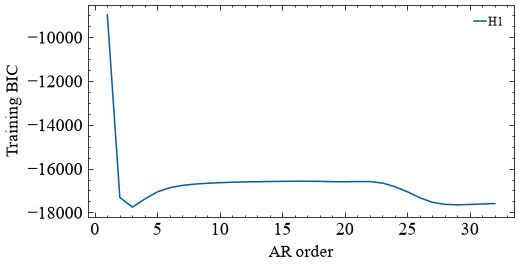

In [4]:
from scipy.linalg import solve_toeplitz

def select_ar(training, max_order=32):
    """Bounded Yule-Walker candidates; conditional Gaussian BIC on common samples."""
    scale = float(np.std(training))
    x = (training - np.mean(training))/scale
    acov = signal.correlate(x, x, mode="full", method="fft")[len(x)-1:len(x)+max_order]/len(x)
    candidates = []
    for order in range(1, max_order+1):
        try:
            coefficients = solve_toeplitz(acov[:order], acov[1:order+1])
            radius = float(np.max(abs(np.roots(np.r_[1., -coefficients]))))
            residual = signal.lfilter(np.r_[1., -coefficients], [1.], x)[max_order:]
            variance = float(np.mean(residual**2))
            bic = len(residual)*np.log(variance) + order*np.log(len(residual))
            if radius >= 1 or variance <= 0 or not np.isfinite(bic):
                raise ValueError("nonstationary or nonfinite candidate")
            candidates.append(dict(order=order, bic=bic, coefficients=coefficients,
                                   variance=variance*scale**2, radius=radius, status="ok"))
        except (ValueError, np.linalg.LinAlgError) as error:
            candidates.append(dict(order=order, bic=np.inf, status=str(error)))
    usable = [row for row in candidates if row["status"] == "ok"]
    if not usable:
        raise RuntimeError("No stable AR candidate; inspect training data")
    return min(usable, key=lambda row: row["bic"]), candidates

models, diagnostics = [], []
for channel in range(training.shape[1]):
    model, candidates = select_ar(training[:, channel])
    models.append(model); diagnostics.append(candidates)
    print(DETECTORS[channel], "AR order", model["order"], "root radius", model["radius"],
          "rejected", sum(row["status"] != "ok" for row in candidates))

def ar_reference(f):
    matrix = np.zeros((len(f), len(models), len(models)), complex)
    for j, model in enumerate(models):
        phase = np.exp(-2j*np.pi*f[:, None]*np.arange(1, model["order"]+1)/fs)
        denominator = abs(1-phase@model["coefficients"])**2
        matrix[:, j, j] = model["variance"]/(fs*denominator)  # two-sided density
    return matrix

fig, ax = plt.subplots(figsize=(5, 2.5))
for detector, rows in zip(DETECTORS, diagnostics):
    ax.plot([r["order"] for r in rows], [r["bic"] for r in rows], label=detector)
ax.set(xlabel="AR order", ylabel="Training BIC"); ax.legend(); plt.show()


## Fit the spectrum

In [5]:
start = perf_counter()
estimator = PSDEstimator(data, fs=fs, reference_psd=ar_reference,
                         parallel_rows=True, fmin_for_analysis=20., fmax_for_analysis=200., **BUDGET)
_ = estimator.run(lr=.003)  # Explicit rate: no costly hyperparameter search.
runtime = perf_counter() - start
assert np.all(np.isfinite(estimator.pointwise_ci))
assert np.all(np.isfinite(estimator.inference_runner.kdl_losses))
print(f"{len(data)} samples × {data.shape[1]} channels; fit {runtime:.2f} s")
if estimator.parallel_rows:
    print("Independent vmapped Cholesky-row dimensions:", estimator.inference_runner.row_dimensions)


20:10:40|SGVB-PSD|INFO| Dividing data (2048, 1) into (2, 1024, 1) chunks
20:10:40|SGVB-PSD|INFO| Reducing the number of frequencies to be analyzed from 512 to 200.0...
20:10:40|SGVB-PSD|INFO| Final PSD will be of shape: 360 x 1 x 1
20:10:40|SGVB-PSD|WARNING| Input data not standardised!
20:10:40|SGVB-PSD|INFO| Using provided learning rate: 0.003
20:10:40|SGVB-PSD|INFO| Training model
20:10:41|SGVB-PSD|INFO| Model trained in 0.98s
20:10:41|SGVB-PSD|INFO| Computing posterior PSDs
2048 samples × 1 channels; fit 2.05 s
Independent vmapped Cholesky-row dimensions: (19,)


## Plot the results

The saved figures show the fitted spectra and pointwise 90% variational intervals.

In [6]:
def show_fit(estimator, data, labels, truth=None, reference=None):
    """Two-sided densities and magnitude-squared coherence, no hidden rescaling."""
    from matplotlib.ticker import NullFormatter
    p = data.shape[1]
    fig, axes = plt.subplots(p, 1, figsize=(7.2, 2.8*p), squeeze=False)
    for i, ax in enumerate(axes[:, 0]):
        fw, pw = signal.welch(data[:, i], fs=estimator.fs, window="boxcar",
                              nperseg=estimator.nt_per_chunk, noverlap=0,
                              detrend=False, return_onesided=False)
        keep = (fw >= estimator.freq[0]) & (fw <= estimator.freq[-1])
        ax.loglog(fw[keep], pw[keep], color="0.65", lw=.7, label="Blocked periodogram")
        q = estimator.pointwise_ci[:, :, i, i].real
        ax.fill_between(estimator.freq, q[0], q[2], alpha=.25)
        ax.loglog(estimator.freq, q[1], label="SGVB median")
        if truth is not None:
            ax.loglog(estimator.freq, truth(estimator.freq)[:, i, i].real, "k--", lw=1, label="Known simulation truth")
        if reference is not None:
            ax.loglog(estimator.freq, reference(estimator.freq)[:, i, i].real, ":", color="C2", lw=1, label="Fixed reference")
        ax.set(title=labels[i], xlabel="Frequency [Hz]", ylabel="Two-sided PSD [input units²/Hz]")
        ticks = np.geomspace(estimator.freq[0], estimator.freq[-1], 4)
        ax.set_xticks(ticks, labels=[f"{f:.2g}" for f in ticks])
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.tick_params(axis="both", labelsize=10)
        ax.grid(which="major", alpha=.2)
        ax.legend(fontsize=9)
    fig.tight_layout(); plt.show()
    if p > 1:
        fig, ax = plt.subplots(figsize=(7.2, 3.4))
        s = estimator.psd_all
        for i in range(p):
            for j in range(i):
                coh = abs(s[:, :, i, j])**2/(s[:, :, i, i].real*s[:, :, j, j].real)
                q = np.quantile(coh, [.05, .5, .95], axis=0)
                line, = ax.plot(estimator.freq, q[1], label=f"{labels[i]}–{labels[j]}")
                ax.fill_between(estimator.freq, q[0], q[2], alpha=.15, color=line.get_color())
                if truth is not None:
                    known = truth(estimator.freq)
                    known_coh = abs(known[:, i, j])**2/(known[:, i, i].real*known[:, j, j].real)
                    ax.plot(estimator.freq, known_coh, "--", color=line.get_color(), label=f"{labels[i]}–{labels[j]} truth")
        ax.set(xlabel="Frequency [Hz]", ylabel="Magnitude-squared coherence", ylim=(0, 1))
        ax.grid(alpha=.2); ax.legend(fontsize=9); fig.tight_layout(); plt.show()


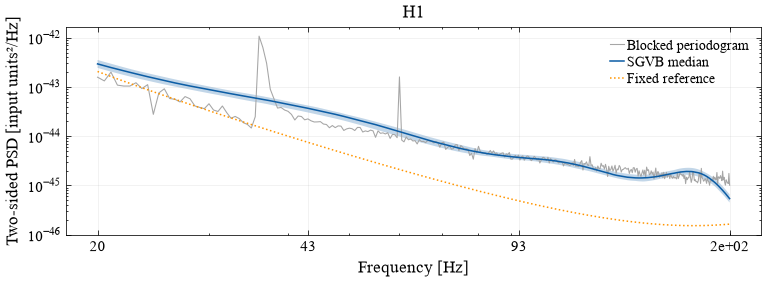

In [7]:
show_fit(estimator, data, list(DETECTORS), reference=ar_reference)


## Interpretation and budget

The shaded bands are pointwise 90% variational intervals. Cheap settings
show the workflow; they do not establish convergence or calibrated coverage.
Increase the data duration, basis size and optimization budgets only for an
explicit analysis/validation plan. Compilation is included in the first-fit
time. JAX batches rows with `vmap`; actual CPU/GPU scheduling is device dependent.
Each row still includes regression on preceding channels, so cross-spectra
are retained. This is modified-Cholesky SGVB, not the removed eigenbasis mode or the
collapsed conditional-theta method in LogPSplinePSD.
